# Exploratory Data Analysis of a Three-Class Morphometric Dataset
Class frequencies, summary statistics and IQR, and univariate, bivariate and multivariate plots
(histogram, box, violin, scatter, density contours, hexbin, correlation heat map, pair plot).

Run from this folder:  python exploratory_data_analysis.py   (figures are written to ./figures)

In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

HERE = os.path.dirname(os.path.abspath(__file__)) if "__file__" in globals() else "."
DATA = os.path.join(HERE, "data")
FIG = os.path.join(HERE, "figures")
os.makedirs(FIG, exist_ok=True)

PAL = {"A": "#2a78d6", "B": "#eb6834", "C": "#1baf7a"}
FEATS = ["Feature 1", "Feature 2", "Feature 3", "Feature 4"]
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

df = pd.read_csv(os.path.join(DATA, "eda_dataset.csv"))
df = df.sort_values("Classes")

### Class balance and summary statistics

In [2]:
print("Samples per class:\n", df["Classes"].value_counts().sort_index(), "\n")
print("Sex per class:\n", pd.crosstab(df["Classes"], df["Sex"]), "\n")
desc = df[FEATS].describe()
iqr = df[FEATS].quantile(0.75) - df[FEATS].quantile(0.25)
print(desc.round(3), "\n")
print("Interquartile range:\n", iqr, "\n")
print("Per-class means:\n", df.groupby("Classes")[FEATS].mean().round(2), "\n")

Samples per class:
 Classes
A    151
B    123
C     68
Name: count, dtype: int64 

Sex per class:
 Sex      .  FEMALE  MALE
Classes                 
A        0      73    73
B        1      58    61
C        0      34    34 

       Feature 1  Feature 2  Feature 3  Feature 4
count    342.000    342.000    342.000    342.000
mean      43.922     17.151    200.915   4201.754
std        5.460      1.975     14.062    801.955
min       32.100     13.100    172.000   2700.000
25%       39.225     15.600    190.000   3550.000
50%       44.450     17.300    197.000   4050.000
75%       48.500     18.700    213.000   4750.000
max       59.600     21.500    231.000   6300.000 

Interquartile range:
 Feature 1       9.275
Feature 2       3.100
Feature 3      23.000
Feature 4    1200.000
dtype: float64 

Per-class means:
          Feature 1  Feature 2  Feature 3  Feature 4
Classes                                            
A            38.79      18.35     189.95    3700.66
B            47.50   

### Univariate views

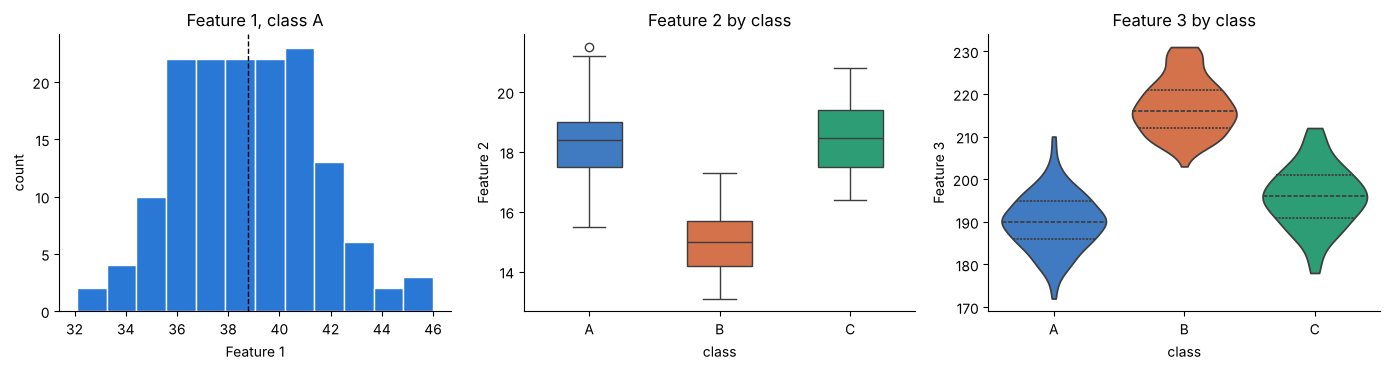

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
a = df[df["Classes"] == "A"]["Feature 1"]
axes[0].hist(a, bins=12, color=PAL["A"], edgecolor="white")
axes[0].axvline(a.mean(), color="black", lw=1, ls="--")
axes[0].set(title="Feature 1, class A", xlabel="Feature 1", ylabel="count")
sns.boxplot(data=df, x="Classes", y="Feature 2", hue="Classes", palette=PAL, ax=axes[1], legend=False,
            width=0.5)
axes[1].set(title="Feature 2 by class", xlabel="class")
sns.violinplot(data=df, x="Classes", y="Feature 3", hue="Classes", palette=PAL, ax=axes[2], legend=False,
               inner="quartile", cut=0)
axes[2].set(title="Feature 3 by class", xlabel="class")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "univariate.png"), dpi=160)
plt.show()

### Bivariate views

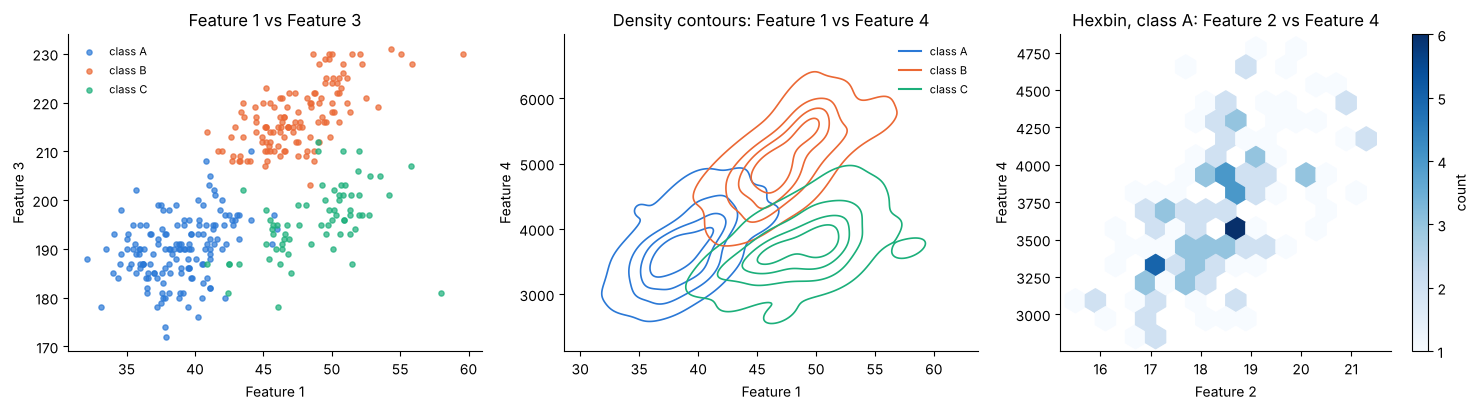

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for c, g in df.groupby("Classes"):
    axes[0].scatter(g["Feature 1"], g["Feature 3"], s=14, alpha=0.7, color=PAL[c], label=f"class {c}")
    sns.kdeplot(x=g["Feature 1"], y=g["Feature 4"], levels=5, color=PAL[c], ax=axes[1], linewidths=1.2)
axes[0].set(title="Feature 1 vs Feature 3", xlabel="Feature 1", ylabel="Feature 3")
axes[0].legend(frameon=False, fontsize=8)
axes[1].set(title="Density contours: Feature 1 vs Feature 4", xlabel="Feature 1", ylabel="Feature 4")
for c in PAL:
    axes[1].plot([], [], color=PAL[c], label=f"class {c}")
axes[1].legend(frameon=False, fontsize=8)
A = df[df["Classes"] == "A"]
hb = axes[2].hexbin(A["Feature 2"], A["Feature 4"], gridsize=15, cmap="Blues", mincnt=1)
fig.colorbar(hb, ax=axes[2], label="count")
axes[2].set(title="Hexbin, class A: Feature 2 vs Feature 4", xlabel="Feature 2", ylabel="Feature 4")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "bivariate.png"), dpi=160)
plt.show()

### Correlation and pair plot

Correlation matrix:
            Feature 1  Feature 2  Feature 3  Feature 4
Feature 1      1.000     -0.235      0.656      0.595
Feature 2     -0.235      1.000     -0.584     -0.472
Feature 3      0.656     -0.584      1.000      0.871
Feature 4      0.595     -0.472      0.871      1.000 

Within-class correlation, Feature 1 vs Feature 2:
  class A: 0.391
  class B: 0.643
  class C: 0.654


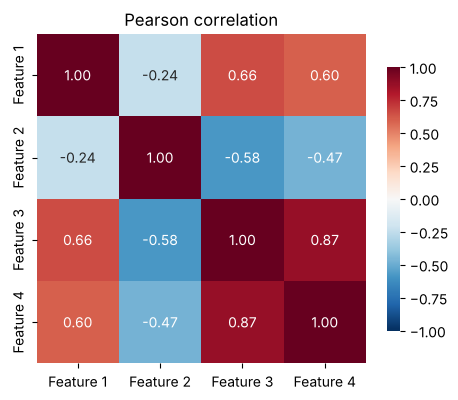

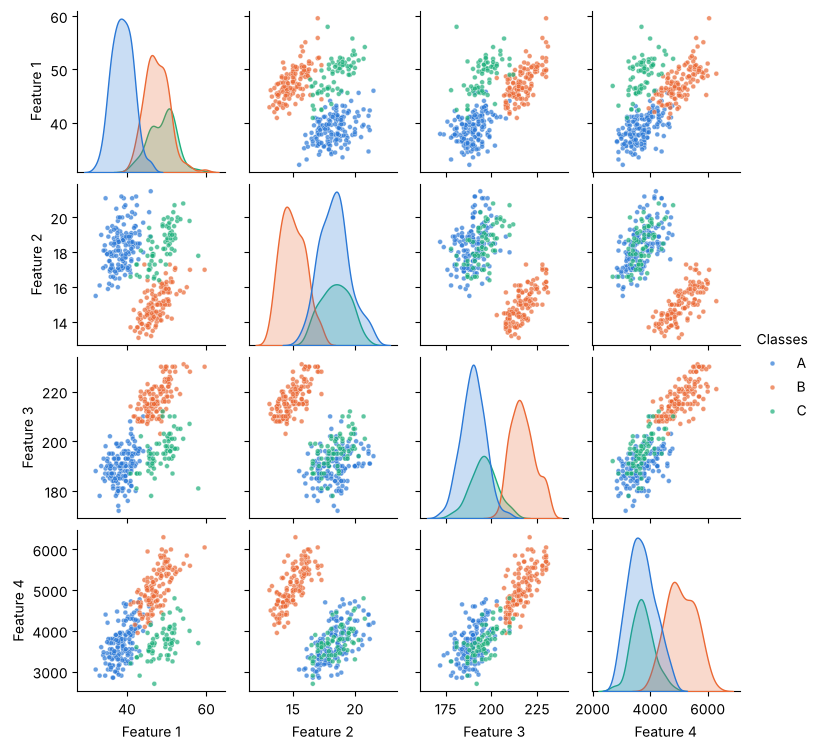

In [5]:
corr = df[FEATS].corr()
print("Correlation matrix:\n", corr.round(3), "\n")
print("Within-class correlation, Feature 1 vs Feature 2:")
for c, g in df.groupby("Classes"):
    print(f"  class {c}: {g['Feature 1'].corr(g['Feature 2']):.3f}")

fig, ax = plt.subplots(figsize=(4.8, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, ax=ax,
            cbar_kws={"shrink": 0.8})
ax.set_title("Pearson correlation")
plt.tight_layout()
plt.savefig(os.path.join(FIG, "correlation.png"), dpi=160)
plt.show()

g = sns.pairplot(df, vars=FEATS, hue="Classes", palette=PAL, plot_kws={"s": 12, "alpha": 0.7},
                 height=1.9)
g.savefig(os.path.join(FIG, "pairplot.png"), dpi=150)
plt.show()